# Навчання моделі ймовірності коректної прив’язки

Модель прогнозує ймовірність події: **SIFT прийняв горизонтальну прив’язку з похибкою до 3 м**. Значення 3 м — критерій оцінювання в датасеті, а не встановлена вимога безпеки польоту.

Порівнюємо три варіанти: одна стала частота успіху; логістична регресія за умовами пошуку; така сама регресія з додатковою ознакою деталізації карти. Логістична регресія — статистична модель, що перетворює числові ознаки на ймовірність події.

Навчання на Scene_05, порівняння на Scene_07. Scene_21 не читається і не зіставляється. Після порівняння всі три зафіксовані варіанти навчаються на обох робочих сценах для майбутньої остаточної перевірки.

Навчання реальних таблиць виконуємо в hosted Colab. GPU та ZIP сцен не потрібні. Вручну скопіюйте оновлений `outcome_model.py` і цей notebook у Drive. Із локальної папки `results/vml/working-review-v1` скопіюйте **features.csv, labels.csv, feature_spec.json** у `PhD/proj/vml/working-review-v1` у Drive. Контрольні суми таблиць перевіряються автоматично.


In [1]:
import os
from pathlib import Path
if not os.environ.get('COLAB_RELEASE_TAG') or not Path('/content').is_dir():
    raise RuntimeError('Use a hosted Google Colab runtime, not a local runtime.')
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Шляхи та імпорт

`DATASET_DIR` містить три невеликі файли навчальних даних. `OUTPUT_DIR` — новий окремий каталог моделей. Попередні результати зіставлення й аудиту не змінюються.

Використовуються NumPy, SciPy та Matplotlib. У попередній Colab-сесії вони вже встановлені. Якщо імпорт повідомить про відсутню бібліотеку, встановіть її та повторіть імпорт. Великі нейромережеві ваги не завантажуються.


In [2]:
REPO_ROOT = Path('/content/drive/MyDrive/PhD/proj')
DATASET_DIR = REPO_ROOT / 'vml/working-review-v1'
OUTPUT_DIR = REPO_ROOT / 'vml/correct-fix-model-v1'
import sys, importlib, json
sys.path.insert(0, str(REPO_ROOT))
importlib.invalidate_caches()
modeling = importlib.import_module('scripts.pipeline.chance_constrained.visual_map_localization.outcome_model')
importlib.reload(modeling)
import numpy as np, scipy, matplotlib
print('Versions:', {'numpy': np.__version__, 'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__})
spec, rows, y, train_mask = modeling.load_tables(DATASET_DIR)
for split, mask in [('train_Scene_05', train_mask), ('validation_Scene_07', ~train_mask)]:
    print(split, 'rows:', int(mask.sum()), 'successes:', int(y[mask].sum()), 'non-successes:', int(mask.sum()-y[mask].sum()))
print('Predictor lists:', modeling.MODEL_INPUTS)


Versions: {'numpy': '2.1.3', 'scipy': '1.16.3', 'matplotlib': '3.10.0'}
train_Scene_05 rows: 787 successes: 183 non-successes: 604
validation_Scene_07 rows: 209 successes: 159 non-successes: 50
Predictor lists: {'constant': (), 'geometry': ('log_agl_m', 'map_coverage', 'log_search_to_footprint_ratio', 'log_projection_condition', 'log_footprint_area_m2', 'log_query_bbox_pixels', 'log_reference_crop_pixels'), 'geometry_and_map_features': ('log_agl_m', 'map_coverage', 'log_search_to_footprint_ratio', 'log_projection_condition', 'log_footprint_area_m2', 'log_query_bbox_pixels', 'log_reference_crop_pixels', 'log_reference_keypoint_density_mpx')}


## 2. Навчити та зафіксувати моделі

Сила регуляризації дорівнює 1 і однакова для обох регресій. Регуляризація обмежує величини коефіцієнтів, щоб зменшити підлаштування під окремі кадри. Вільний зсув не штрафується. Масштабування ознак обчислюється лише за навчальною сценою; дані Scene_07 до нього не потрапляють.

Спочатку навчаються моделі на Scene_05 та оцінюються на Scene_07. Варіант із найменшою логарифмічною втратою позначається як обраний. **Логарифмічна втрата** оцінює відповідність прогнозованих імовірностей фактичним подіям; менше — краще. Потім усі три зафіксовані варіанти навчаються на Scene_05 + Scene_07, а їхні коефіцієнти зберігаються для остаточного тесту.

Повторний запуск із тими самими таблицями й кодом може відновити експорти. Якщо код, дані або версії бібліотек змінилися, потрібен новий OUTPUT_DIR. Одночасно цей каталог має використовувати лише одна сесія.


In [3]:
summary = modeling.run_training(DATASET_DIR, OUTPUT_DIR)
print('Training status:', summary['training_status'])
print('Selected by Scene_07 log loss:', summary['selected_by_validation'])
print('Map-feature log-loss gain over geometry:', summary['map_feature_validation_log_loss_gain'])
for name, result in summary['evaluations'].items():
    print(name, {key: result[key] for key in ('sample_count', 'log_loss', 'brier_score', 'roc_auc', 'outside_training_feature_ranges_count')})


Training status: working_scene_evaluated_models_frozen
Selected by Scene_07 log loss: constant
Map-feature log-loss gain over geometry: -0.5947158506665007
constant {'sample_count': 209, 'log_loss': 1.1730750991421557, 'brier_score': 0.46103561441421, 'roc_auc': 0.5, 'outside_training_feature_ranges_count': 0}
geometry {'sample_count': 209, 'log_loss': 1.7398723016659394, 'brier_score': 0.5647024315126967, 'roc_auc': 0.8163522012578617, 'outside_training_feature_ranges_count': 55}
geometry_and_map_features {'sample_count': 209, 'log_loss': 2.33458815233244, 'brier_score': 0.5981065635207986, 'roc_auc': 0.8729559748427673, 'outside_training_feature_ranges_count': 153}


## 3. Прочитати результат

Менші **log loss** і **Brier score** означають кращі ймовірнісні прогнози. Brier score — середня квадратична різниця між прогнозованою ймовірністю та результатом 0 або 1. **ROC AUC** показує здатність ранжувати успішні й неуспішні випадки; він не доводить правильності самих імовірностей.

**Калібрування ймовірностей** означає відповідність прогнозу фактичній частоті. Наприклад, у групі багатьох спроб із прогнозом близько 70% очікується близько 70% успіхів. Графік показує групи прогнозів Scene_07, але не є автоматичним доказом надійності моделі на всіх місцевостях.

Позитивний `map_feature_validation_log_loss_gain` означає меншу втрату моделі з ознакою карти на цій перевірочній сцені. Від’ємний означає відсутність такого покращення. Кращий результат не гарантується; вибирати ознаки за результатами Scene_21 не можна.

`outside_training_feature_ranges_count` показує кількість кадрів, для яких хоча б одна ознака поза діапазоном Scene_05. Це груба діагностика перенесення, а не доведена межа застосовності.


# Correct-fix probability model training

Target: matcher accepts a horizontal fix with dataset-relative error <=3 m.
Training: Scene_05. Validation: Scene_07. Scene_21 has not been read or matched.
Fixed L2 strength 1.0, summed logistic loss, unpenalized intercept, training-only standardization.
Lower log loss and Brier score are better. AUC measures ranking, not calibration.

| Model | Validation log loss | Brier score | ROC AUC | Out-of-range validation rows |
| --- | ---: | ---: | ---: | ---: |
| constant | 1.173075 | 0.461036 | 0.500000 | 0 |
| geometry | 1.739872 | 0.564702 | 0.816352 | 55 |
| geometry_and_map_features | 2.334588 | 0.598107 | 0.872956 | 153 |

Selected by validation log loss: constant. All three fixed candidates are refitted on both working scenes and frozen for final comparison.
Observed map-feature log-loss gain over geometry: -0.594716. This is a point comparison on one validation scene, not a statistical significance claim.

Inspect calibration.png and calibration.csv: predicted probabilities should agree with observed frequencies. No automatic calibration-success certificate is inferred from small bins.
Feature extraction uses supplied camera geometry and the reference map; actual query feature counts and all post-match diagnostics are excluded.
Covariance is fixed at sigma=20 m per XY axis. Predicting a growing uncertainty along a route requires additional training conditions.
This model can become an input to correction-opportunity evaluation after independent testing and state-transition integration. It is not connected to the planner and does not certify route safety.
Final Scene_21 evaluation remains pending. Do not tune candidates using that scene.
Model exports use JSON coefficients and standardization parameters, without pickle or a scikit-learn dependency.


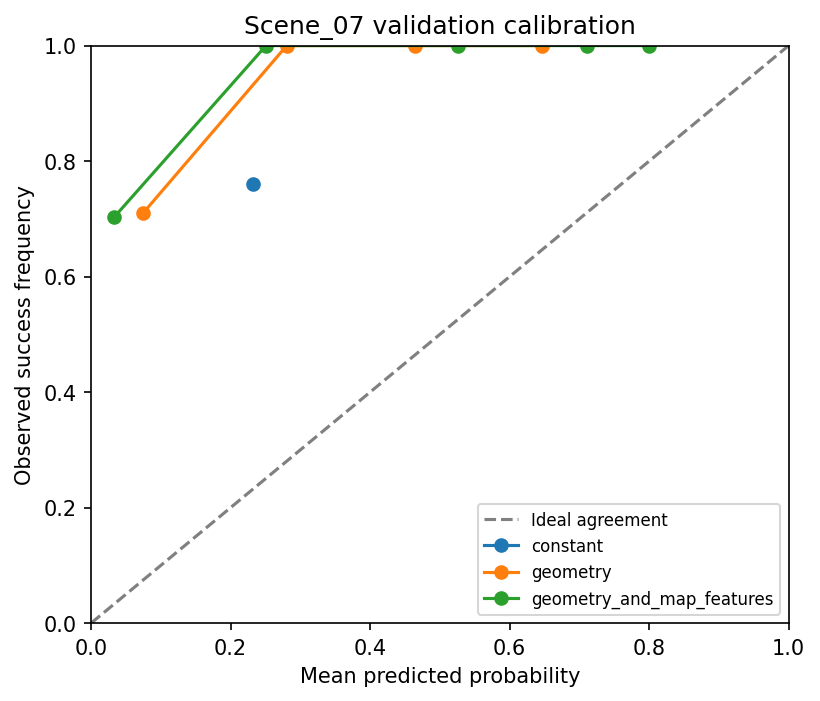

Final test evaluated: False
Deployment status: research_only


In [4]:
from IPython.display import display, Markdown, Image
display(Markdown((OUTPUT_DIR / 'report.md').read_text(encoding='utf-8')))
display(Image(filename=str(OUTPUT_DIR / 'calibration.png')))
manifest = modeling._read(OUTPUT_DIR / 'manifest.json')
print('Final test evaluated:', manifest['final_test_evaluated'])
print('Deployment status:', manifest['deployment_status'])


## 4. Місце моделі в плануванні маршруту

Для запланованої спроби корекції планувальник має визначити очікувану висоту, орієнтацію камери, неточність положення та потрібний фрагмент карти. За цими умовами обчислюються ознаки. Модель прогнозує ймовірність прив’язки з похибкою до 3 м.

Потім окрема модель навігації повинна врахувати, як правильна корекція зменшує похибку, як відмова залишає її накопичуватися і як помилково прийнята корекція змінює положення. За цим можна порівнювати маршрути з різними можливостями корекції. Поточний планувальник у цьому notebook не змінюється.

**Перша модель оцінює лише ймовірність коректної прив’язки.** Її доповнення до 1 об’єднує відмови та прийняті прив’язки з похибкою понад 3 м. Вона ще не описує ці наслідки окремо і не оцінює ймовірність прибуття в ціль. Перемножувати її прогнози вздовж маршруту й називати це ймовірністю безпечного польоту не можна.

У даних початкова невизначеність фіксована: стандартне відхилення 20 м по кожній осі. Для прогнозу при зростанні похибки вздовж маршруту потрібен окремий експеримент із кількома рівнями невизначеності. Ознаки майбутнього кадру не використовуються; ознака деталізації обчислюється з відомої карти.

Поки немає остаточної перевірки на Scene_21, експорт має `validation_passed=false` і `deployment_status=research_only`. Це означає незавершену перевірку моделі, а не помилку виконання навчання.


## Що передати для розбору

Збережіть виконаний notebook із виводами. Завантажте всю нову папку `vml/correct-fix-model-v1` до локальної `results/vml/`.

У ній будуть: `run.json`, `summary.json`, `report.md`, `validation_predictions.csv`, `calibration.csv/png`, `manifest.json`, моделі для перевірки в `validation_models/` і зафіксовані моделі в `frozen_models/`. Моделі містять коефіцієнти й параметри масштабування у JSON, без pickle.

Остаточний запуск Scene_21 виконаємо після розбору цих результатів і фіксації протоколу. Для цього навчання архіви сцен не потрібні.
